# Imports

In [1]:
from pathlib import Path
import sys
from os import makedirs, environ
from datetime import UTC, datetime

environ["HF_HOME"] = "./data/huggingface"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence
from torch.utils.data import Dataset, DataLoader
from torch.utils.tensorboard import SummaryWriter

from datasets import load_dataset
from transformers import AutoTokenizer

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score,
    RocCurveDisplay,
    f1_score,
)

sys.path.insert(0, str(Path.cwd() / "NN"))
from utils import train_one_epoch, validate_one_epoch, fit

In [2]:
SEED = 42

np.random.seed(SEED)
RNG = np.random.default_rng(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print(f"Torch version: {torch.__version__}")
print(f"Device: {DEVICE}")

if DEVICE == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Torch version: 2.15.0+cu132
Device: cuda
GPU: NVIDIA GeForce RTX 5070


# Dataset

Load the dataset (we will be using [go_emotions](https://huggingface.co/datasets/google-research-datasets/go_emotions)). Pretokenize data or make a loader that tokenizes the sentenses as you iterate through the dataset. Implement two datasets: variable and fixed sentence length (in tokens). Don't forget to split the dataset into train and test subsets

In [3]:
PATH_2_DATASET = Path("../data")
makedirs(PATH_2_DATASET, exist_ok=True)


dataset = load_dataset(
    'google-research-datasets/go_emotions',
    name='raw',
    split='train',
    cache_dir=PATH_2_DATASET
)

In [4]:
emotions = [
    'admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring', 'confusion', 'curiosity',
    'desire', 'disappointment', 'disapproval', 'disgust', 'embarrassment', 'excitement', 'fear',
    'gratitude', 'grief', 'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization', 'relief',
    'remorse', 'sadness', 'surprise', 'neutral'
]

In [5]:
tokenizer = AutoTokenizer.from_pretrained('gpt2')
tokenizer.pad_token = tokenizer.eos_token

In [6]:
dataset_pandas = dataset.to_pandas()
dataset_pandas.columns

Index(['text', 'id', 'author', 'subreddit', 'link_id', 'parent_id',
       'created_utc', 'rater_id', 'example_very_unclear', 'admiration',
       'amusement', 'anger', 'annoyance', 'approval', 'caring', 'confusion',
       'curiosity', 'desire', 'disappointment', 'disapproval', 'disgust',
       'embarrassment', 'excitement', 'fear', 'gratitude', 'grief', 'joy',
       'love', 'nervousness', 'optimism', 'pride', 'realization', 'relief',
       'remorse', 'sadness', 'surprise', 'neutral'],
      dtype='str')

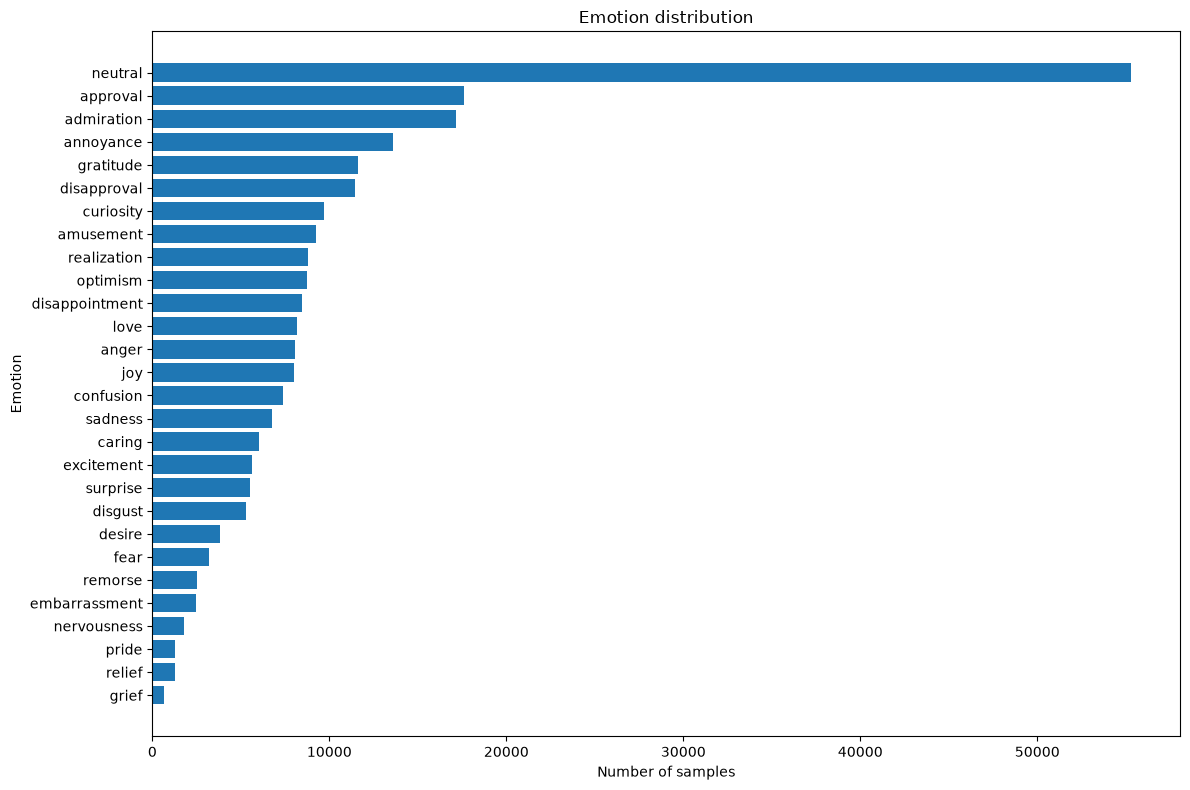

In [7]:
emotion_counts = dataset_pandas[emotions].sum().sort_values(ascending=True)

plt.figure(figsize=(12, 8))

plt.barh(
    emotion_counts.index,
    emotion_counts.values
)

plt.title("Emotion distribution")
plt.xlabel("Number of samples")
plt.ylabel("Emotion")

plt.tight_layout()
plt.show()

In [8]:
len_text_tokens = [len(tokenizer.encode(text)) for text in dataset_pandas["text"]]

print("Describe:")
print(f"Max: {np.max(len_text_tokens)}")
print(f"Mean: {np.mean(len_text_tokens)}")
print(f"Median: {np.median(len_text_tokens)}")
print(f"95 percentile: {np.percentile(len_text_tokens, q=95)}")
print(f"99 percentile: {np.percentile(len_text_tokens, q=99)}")
print(f"99.9 percentile: {np.percentile(len_text_tokens, q=99.9)}")


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1435 > 1024). Running this sequence through the model will result in indexing errors


Describe:
Max: 1435
Mean: 17.111918570245
Median: 17.0
95 percentile: 31.0
99 percentile: 35.0
99.9 percentile: 44.0


In [9]:
MAX_LENGTH = 44

encoded = tokenizer(
    dataset_pandas['text'].tolist(),
    truncation=True,
    max_length=MAX_LENGTH,
    padding=False
)

Text(0.5, 1.0, 'Distribution of emotions per text')

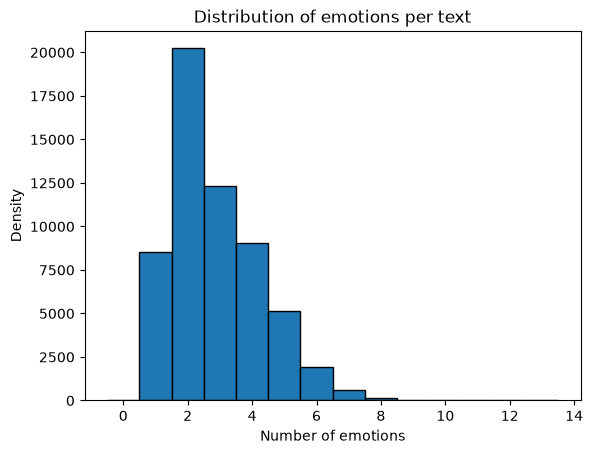

In [10]:
grouped = (
    dataset_pandas
    .groupby("id")
    .agg({
        "text": "first",
        **{emotion: "max" for emotion in emotions}
    })
    .reset_index()
)

values = grouped[emotions].to_numpy().sum(axis=1)
plt.hist(
    values,
    bins=np.arange(-0.5, values.max() + 1.5, 1),
    edgecolor='black',
    linewidth=1
)

plt.xlabel("Number of emotions")
plt.ylabel("Density")
plt.title("Distribution of emotions per text")

# Dataset

In [11]:
class GoEmotionsDataset(Dataset):
    def __init__(
        self,
        x: pd.Series,
        y: np.ndarray,
        tokenizer,
        max_seq_length: int = 44,
    ):
        self.raw_text_tokens = [
            tokenizer.encode(text)[:max_seq_length]
            for text in x
        ]
        self.y = torch.tensor(y, dtype=torch.float32)
        self.lengths = [len(tokens) for tokens in self.raw_text_tokens]

    def __len__(self):
        return len(self.raw_text_tokens)

    def __getitem__(self, idx):
        return (
            torch.tensor(self.raw_text_tokens[idx], dtype=torch.long),
            self.y[idx],
        )

In [12]:
class GoEmotionsCollator:
    def __init__(
        self,
        pad_token_id: int,
        max_seq_length: int = 44,
        fixed_seq_length: bool = True,
    ):
        self.pad_token_id = pad_token_id
        self.max_seq_length = max_seq_length
        self.fixed_seq_length = fixed_seq_length

    def __call__(self, batch):
        sequences, labels = zip(*batch)
        lengths = torch.tensor([len(seq) for seq in sequences], dtype=torch.long)

        if self.fixed_seq_length:
            max_len = self.max_seq_length
        else:
            max_len = max(lengths).item()

        x = torch.full(
            (len(sequences), max_len),
            self.pad_token_id,
            dtype=torch.long,
        )

        for i, seq in enumerate(sequences):
            seq = seq[:max_len]
            x[i, :len(seq)] = seq

        return x, torch.stack(labels), lengths


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    grouped["text"], grouped[emotions].to_numpy(), test_size=0.2, random_state=42
)

In [14]:
MAX_LENGTH = 44
BATCH_SIZE = 128

train_dataset = GoEmotionsDataset(
    x=X_train,
    y=y_train,
    tokenizer=tokenizer,
    max_seq_length=MAX_LENGTH,
)

test_dataset = GoEmotionsDataset(
    x=X_test,
    y=y_test,
    tokenizer=tokenizer,
    max_seq_length=MAX_LENGTH,
)


In [15]:
fixed_len = GoEmotionsCollator(
    pad_token_id=tokenizer.pad_token_id,
    max_seq_length=MAX_LENGTH,
    fixed_seq_length=True,
)

variable_len = GoEmotionsCollator(
    pad_token_id=tokenizer.pad_token_id,
    max_seq_length=MAX_LENGTH,
    fixed_seq_length=False,
)

In [16]:
loader = {
    "fixed": {
        "train_loader": DataLoader(
            train_dataset,
            batch_size=BATCH_SIZE,
            shuffle=True,
            collate_fn=fixed_len,
        ),
        "test_loader": DataLoader(
            test_dataset,
            batch_size=BATCH_SIZE,
            shuffle=False,
            collate_fn=fixed_len,
        ),
    },
    "variable": {
        "train_loader": DataLoader(
            train_dataset,
            batch_size=BATCH_SIZE,
            shuffle=True,
            collate_fn=variable_len,
        ),
        "test_loader": DataLoader(
            test_dataset,
            batch_size=BATCH_SIZE,
            shuffle=False,
            collate_fn=variable_len,
        ),
    },
}


In [17]:
x_batch, y_batch, lengths = next(iter(loader["fixed"]["train_loader"]))
x_batch.shape, y_batch.shape, lengths.shape


(torch.Size([128, 44]), torch.Size([128, 28]), torch.Size([128]))

In [18]:
x_batch, y_batch, lengths = next(iter(loader["variable"]["train_loader"]))
x_batch.shape, y_batch.shape, lengths.shape

(torch.Size([128, 36]), torch.Size([128, 28]), torch.Size([128]))

# Model

Implement your model. The model should have the RNN architecture (with LSTM or GRU cells), support stacking and bidirectional feature extraction.

In [19]:
def get_name(prefix: str | None = None, suffix: str | None = None, separator: str = '_') -> str | None:
    return prefix and prefix + separator + suffix or suffix or None

In [20]:
class GoEmotionsRNN(nn.Module):
    def __init__(
        self,
        units: int,
        n_tokens: int,
        n_labels: int,
        pad_token_id: int,
        n_stacks: int = 1,
        bidirectional: bool = False,
        cell_type: str = "LSTM",
        embedding_dim: int = 64,
        dropout: float = 0.5,
        dense_units: int = 128,
    ):
        super().__init__()

        self.bidirectional = bidirectional

        self.embedding = nn.Embedding(
            num_embeddings=n_tokens,
            embedding_dim=embedding_dim,
            padding_idx=pad_token_id,
        )

        if cell_type.upper() == "LSTM":
            self.rnn = nn.LSTM(
                input_size=embedding_dim,
                hidden_size=units,
                num_layers=n_stacks,
                batch_first=True,
                bidirectional=bidirectional,
                dropout=0.0,
            )
        elif cell_type.upper() == "GRU":
            self.rnn = nn.GRU(
                input_size=embedding_dim,
                hidden_size=units,
                num_layers=n_stacks,
                batch_first=True,
                bidirectional=bidirectional,
                dropout=0.0,
            )
        else:
            raise ValueError("cell_type must be nn.LSTM or nn.GRU")

        rnn_output_dim = units * (2 if bidirectional else 1)

        self.dropout1 = nn.Dropout(dropout)
        self.fc1 = nn.Linear(rnn_output_dim, dense_units)
        self.dropout2 = nn.Dropout(0.3)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(dense_units, n_labels)

    def forward(self, x, lengths):
        x = self.embedding(x)
        packed_x = pack_padded_sequence(
            x,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False,
        )

        if isinstance(self.rnn, nn.LSTM):
            _, (hidden, _) = self.rnn(packed_x)
        else:
            _, hidden = self.rnn(packed_x)

        if self.bidirectional:
            hidden = torch.cat((hidden[-2], hidden[-1]), dim=1)
        else:
            hidden = hidden[-1]

        x = self.dropout1(hidden)
        x = self.relu(self.fc1(x))
        x = self.dropout2(x)
        return self.fc2(x)

In [ ]:
def get_model(
    units: int,
    n_tokens: int,
    n_labels: int,
    pad_token_id: int,
    name: str,
    n_stacks: int = 1,
    bidirectional: bool = False,
    cell_type: type[nn.Module] = nn.LSTM,
) -> GoEmotionsRNN:
    return GoEmotionsRNN(
        units=units,
        n_tokens=n_tokens,
        n_labels=n_labels,
        pad_token_id=pad_token_id,
        n_stacks=n_stacks,
        bidirectional=bidirectional,
        cell_type=cell_type.__name__,
    )


# Training

Train several models on the two dataset variants. Use either of the cell types (LSTM or GRU)
* Simple RNN (no stacking, one direction)
* Stacked RNN (stacking, one direction)
* Bidirectional RNN (no stacking, bidirectional)
* Stacked Bidirectional RNN (stacking, bidirectional)

In [22]:
model_configs = [
    {
        "units": 64,
        "name": "Simple RNN",
        "bidirectional": False,
        "n_stacks": 1,
        "cell_type": nn.LSTM,
    },
    {
        "units": 64,
        "name": "Stacked RNN",
        "bidirectional": False,
        "n_stacks": 2,
        "cell_type": nn.LSTM,
    },
    {
        "units": 64,
        "name": "Bidirectional RNN",
        "bidirectional": True,
        "n_stacks": 1,
        "cell_type": nn.LSTM,
    },
    {
        "units": 64,
        "name": "Stacked Bidirectional RNN",
        "bidirectional": True,
        "n_stacks": 2,
        "cell_type": nn.LSTM,
    },
]

In [23]:
models = [
    get_model(
        units=config["units"],
        n_tokens=len(tokenizer),
        n_labels=len(emotions),
        pad_token_id=tokenizer.pad_token_id,
        name=config["name"],
        bidirectional=config["bidirectional"],
        n_stacks=config["n_stacks"],
        cell_type=config["cell_type"],
    ).to(DEVICE)
    for config in model_configs
]


TypeError: get_model() got an unexpected keyword argument 'name'

In [ ]:
for config, model in zip(model_configs, models):
    total_params = sum(
        p.numel() for p in model.parameters()
    )

    trainable_params = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )

    print(f"\n{'=' * 50}")
    print(f"Model: {config['name']}")
    print(model)
    print(f"Total parameters: {total_params:,}")
    print(f"Trainable parameters: {trainable_params:,}")


Model: Simple RNN
GoEmotionsRNN(
  (embedding): Embedding(50257, 64, padding_idx=50256)
  (rnn): LSTM(64, 64, batch_first=True)
  (dropout1): Dropout(p=0.5, inplace=False)
  (fc1): Linear(in_features=64, out_features=128, bias=True)
  (dropout2): Dropout(p=0.3, inplace=False)
  (relu): ReLU()
  (fc2): Linear(in_features=128, out_features=28, bias=True)
)
Total parameters: 3,261,660
Trainable parameters: 3,261,660

Model: Stacked RNN
GoEmotionsRNN(
  (embedding): Embedding(50257, 64, padding_idx=50256)
  (rnn): LSTM(64, 64, num_layers=2, batch_first=True)
  (dropout1): Dropout(p=0.5, inplace=False)
  (fc1): Linear(in_features=64, out_features=128, bias=True)
  (dropout2): Dropout(p=0.3, inplace=False)
  (relu): ReLU()
  (fc2): Linear(in_features=128, out_features=28, bias=True)
)
Total parameters: 3,294,940
Trainable parameters: 3,294,940

Model: Bidirectional RNN
GoEmotionsRNN(
  (embedding): Embedding(50257, 64, padding_idx=50256)
  (rnn): LSTM(64, 64, batch_first=True, bidirectional

Which loss should be used to multilabel classification? Which metrics?

In [ ]:
training_configs = {}

for config, model in zip(model_configs, models):
    name = config["name"]
    training_configs[name] = {
        "criterion": nn.BCEWithLogitsLoss(),
        "optimizer": torch.optim.AdamW(
            model.parameters(),
            lr=1e-3,
        ),
    }


In [ ]:
def calculate_metrics(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)

    return {
        "auc": roc_auc_score(y_true, y_prob, average="macro"),
        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0,
        ),
        "f1_micro": f1_score(
            y_true,
            y_pred,
            average="micro",
            zero_division=0,
        ),
    }


In [ ]:
for config, model in zip(model_configs, models):
    name = config["name"]

    print(f"\n{name}")
    print("Loss:", training_configs[name]["criterion"])
    print("Optimizer:", training_configs[name]["optimizer"])


Simple RNN
Loss: BCEWithLogitsLoss()
Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.01
)

Stacked RNN
Loss: BCEWithLogitsLoss()
Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.01
)

Bidirectional RNN
Loss: BCEWithLogitsLoss()
Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.01
)

Stacked Bidirectional RNN
Loss: BCEWithLogitsLoss()
Optimizer: AdamW (

In [ ]:
class EarlyStopping:
    def __init__(self, patience: int = 3, mode: str = "max"):
        self.patience = patience
        self.mode = mode
        self.best_score = None
        self.counter = 0
        self.early_stop = False
        self.best_state = None

    def __call__(self, score, model):
        improved = (
            self.best_score is None
            or (score > self.best_score if self.mode == "max" else score < self.best_score)
        )

        if improved:
            self.best_score = score
            self.counter = 0
            self.best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }
        else:
            self.counter += 1
            self.early_stop = self.counter >= self.patience

    def restore_best_weights(self, model):
        model.load_state_dict(self.best_state)


In [ ]:
class ModelCheckpoint:
    def __init__(self, checkpoint_dir, model_name):
        self.checkpoint_dir = Path(checkpoint_dir)
        self.checkpoint_dir.mkdir(parents=True, exist_ok=True)
        self.auc_path = self.checkpoint_dir / f"{model_name}_auc.pt"
        self.f1_path = self.checkpoint_dir / f"{model_name}_f1_macro.pt"
        self.best_auc = float("-inf")
        self.best_f1 = float("-inf")

    def update(self, model, val_auc, val_f1_macro):
        if val_auc > self.best_auc:
            self.best_auc = val_auc
            torch.save(model.state_dict(), self.auc_path)

        if val_f1_macro > self.best_f1:
            self.best_f1 = val_f1_macro
            torch.save(model.state_dict(), self.f1_path)

In [ ]:
LOGS_DIR = Path("../logs")
MODEL_CHECKPOINT_DIR = Path("../checkpoints")

def get_tensorboard_writer(model_name):
    log_dir = (
        LOGS_DIR
        / f"{model_name}-{datetime.now(tz=UTC).strftime('%Y%m%d-%H%M%S')}"
    )
    log_dir.mkdir(parents=True, exist_ok=True)
    return SummaryWriter(log_dir=str(log_dir))


def get_callbacks(model_name, optimizer):
    return {
        "scheduler": torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer,
            mode="max",
            factor=0.5,
            patience=2,
            min_lr=1e-6,
        ),
        "early_stopping": EarlyStopping(
            patience=3,
            mode="max",
        ),
        "checkpoint": ModelCheckpoint(
            checkpoint_dir=MODEL_CHECKPOINT_DIR,
            model_name=model_name,
        ),
        "writer": get_tensorboard_writer(model_name),
    }


In [ ]:
initial_states = [
    {
        key: value.detach().clone()
        for key, value in model.state_dict().items()
    }
    for model in models
]
histories = {}
trained_models = {}

for loader_type in ["fixed", "variable"]:

    for config, model, initial_state in zip(
        model_configs, models, initial_states
    ):
        name = config["name"]
        experiment_name = f"{name}_{loader_type}"

        print(f"\nExperiment: {experiment_name}")

        model.load_state_dict(initial_state)
        model = model.to(DEVICE)

        criterion = nn.BCEWithLogitsLoss()

        optimizer = torch.optim.AdamW(
            model.parameters(),
            lr=1e-3
        )

        callbacks = get_callbacks(
            model_name=experiment_name,
            optimizer=optimizer
        )

        model, history = fit(
            model=model,
            train_loader=loader[loader_type]["train_loader"],
            valid_loader=loader[loader_type]["test_loader"],
            criterion=criterion,
            optimizer=optimizer,
            callbacks=callbacks,
            device=DEVICE,
            calculate_metrics=calculate_metrics,
            epochs=30
        )

        trained_models[experiment_name] = model
        histories[experiment_name] = history


Experiment: Simple RNN_fixed
Epoch [1/30] Train Loss: 0.2008 | Valid Loss: 0.2483 | AUC: 0.7725 | F1 Macro: 0.2582 | F1 Micro: 0.4290
Epoch [2/30] Train Loss: 0.1994 | Valid Loss: 0.2517 | AUC: 0.7704 | F1 Macro: 0.2646 | F1 Micro: 0.4286
Epoch [3/30] Train Loss: 0.1978 | Valid Loss: 0.2543 | AUC: 0.7704 | F1 Macro: 0.2662 | F1 Micro: 0.4338
Epoch [4/30] Train Loss: 0.1963 | Valid Loss: 0.2542 | AUC: 0.7694 | F1 Macro: 0.2666 | F1 Micro: 0.4371

Experiment: Stacked RNN_fixed
Epoch [1/30] Train Loss: 0.2055 | Valid Loss: 0.2535 | AUC: 0.7646 | F1 Macro: 0.2260 | F1 Micro: 0.4073
Epoch [2/30] Train Loss: 0.2037 | Valid Loss: 0.2570 | AUC: 0.7633 | F1 Macro: 0.2294 | F1 Micro: 0.4072
Epoch [3/30] Train Loss: 0.2013 | Valid Loss: 0.2602 | AUC: 0.7628 | F1 Macro: 0.2340 | F1 Micro: 0.4061
Epoch [4/30] Train Loss: 0.1991 | Valid Loss: 0.2618 | AUC: 0.7626 | F1 Macro: 0.2311 | F1 Micro: 0.4072

Experiment: Bidirectional RNN_fixed
Epoch [1/30] Train Loss: 0.2001 | Valid Loss: 0.2350 | AUC: 0.

In [ ]:
results = pd.DataFrame([
    {
        "model": name,
        **history.loc[history["auc"].idxmax()].to_dict()
    }
    for name, history in histories.items()
])

results = results.sort_values(
    "auc",
    ascending=False
).reset_index(drop=True)

results

,model,epoch,train_loss,valid_loss,auc,f1_macro,f1_micro,lr
0,Bidirectional RNN_variable,2.0,0.197845,0.236046,0.791992,0.293410,0.456737,0.001
1,Bidirectional RNN_fixed,2.0,0.197773,0.237285,0.790801,0.284345,0.452798,0.001
2,Stacked Bidirectional RNN_fixed,2.0,0.195149,0.240591,0.786909,0.292905,0.459252,0.001
3,Stacked Bidirectional RNN_variable,1.0,0.198845,0.237756,0.785960,0.284979,0.448070,0.001
4,Simple RNN_fixed,1.0,0.200796,0.248301,0.772525,0.258198,0.429029,0.001
5,Simple RNN_variable,3.0,0.197851,0.249955,0.772060,0.263501,0.427753,0.001
6,Stacked RNN_variable,1.0,0.205746,0.251399,0.765906,0.224958,0.395635,0.001
7,Stacked RNN_fixed,1.0,0.205537,0.253505,0.764580,0.226026,0.407270,0.001


# Evaluation

Evaluate the models you trained on the test datasets. Plot ROC curves for each label (use `sklearn.metrics.RocCurveDisplay`) for each model.

In [ ]:
@torch.no_grad()
def predict_dataset(model, data_loader, device):
    model.eval()

    all_targets = []
    all_probabilities = []

    for x, y, lengths in data_loader:
        x = x.to(device)

        logits = model(x, lengths)
        probabilities = torch.sigmoid(logits)

        all_targets.append(y.numpy())
        all_probabilities.append(probabilities.cpu().numpy())

    y_true = np.concatenate(all_targets)
    y_prob = np.concatenate(all_probabilities)

    return y_true, y_prob

In [ ]:
def plot_roc_curve(
    y_true: np.ndarray,
    y_prob: np.ndarray,
    labels: list[str],
    ax: plt.Axes | None = None,
) -> float:
    '''Plots ROC curves for each of the labels (on a single axes) and outputs mean ROC AUC score.

    Arguments:
        X: model inputs
        y: ground thruths
        model: model to plot the curve for
        ax: axes to plot on

    Returns:
        Mean ROC AUC score'''

    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 8))

    auc_scores = []

    for i, label in enumerate(labels):
        display = RocCurveDisplay.from_predictions(
            y_true[:, i],
            y_prob[:, i],
            name=label,
            ax=ax,
        )

        auc_scores.append(display.roc_auc)

    mean_auc = np.mean(auc_scores)

    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        color="black",
        label="Random classifier",
    )

    ax.set_title(f"ROC curves | Mean ROC AUC: {mean_auc:.4f}")
    ax.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    ax.grid(alpha=0.3)

    return mean_auc

In [ ]:
test_results = {}
predictions = {}

for loader_type in ["fixed", "variable"]:

    test_loader = loader[loader_type]["test_loader"]

    for config in model_configs:
        name = f"{config['name']}_{loader_type}"

        model = trained_models[name]

        y_true, y_prob = predict_dataset(
            model=model,
            data_loader=test_loader,
            device=DEVICE,
        )

        test_results[name] = {
            "auc": roc_auc_score(
                y_true,
                y_prob,
                average="macro",
            )
        }

        predictions[name] = {
            "y_true": y_true,
            "y_prob": y_prob,
        }

        print(f"{name}: ROC AUC = {test_results[name]['auc']:.4f}")

Simple RNN_fixed: ROC AUC = 0.7721
Stacked RNN_fixed: ROC AUC = 0.7659
Bidirectional RNN_fixed: ROC AUC = 0.7920
Stacked Bidirectional RNN_fixed: ROC AUC = 0.7860
Simple RNN_variable: ROC AUC = 0.7721
Stacked RNN_variable: ROC AUC = 0.7659
Bidirectional RNN_variable: ROC AUC = 0.7920
Stacked Bidirectional RNN_variable: ROC AUC = 0.7860


Plot the mean ROC AUC scores. Which model has the highest score? On what kind of dataset?

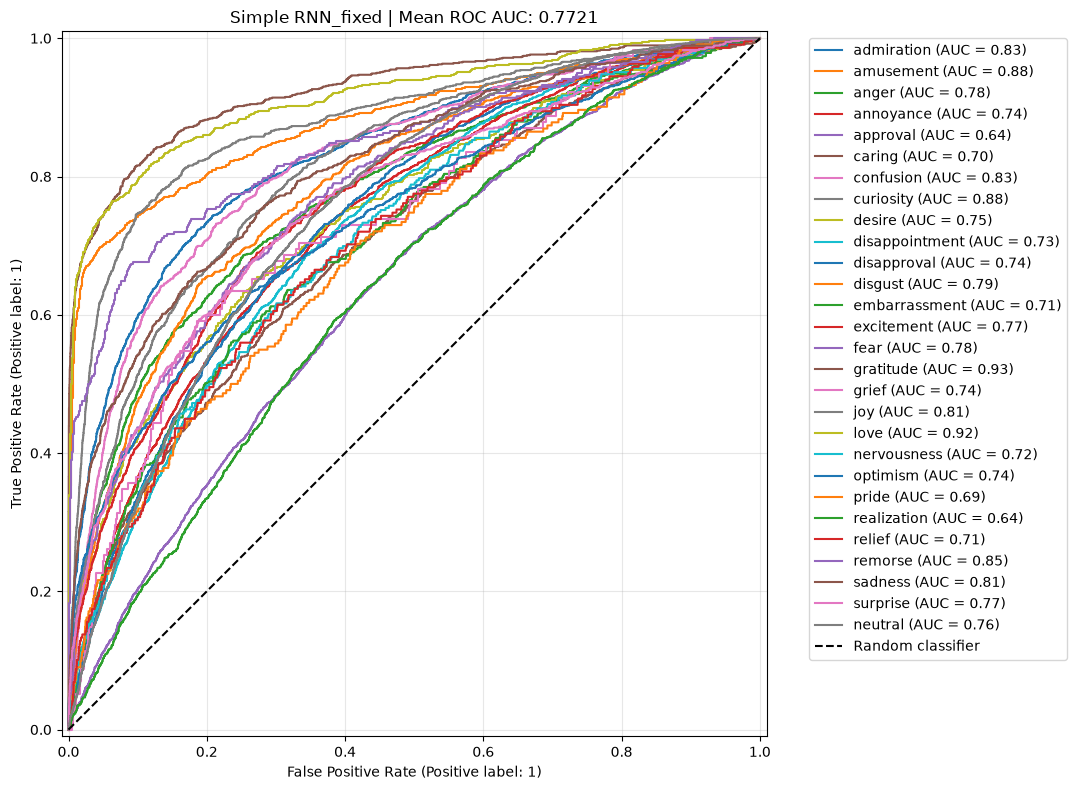

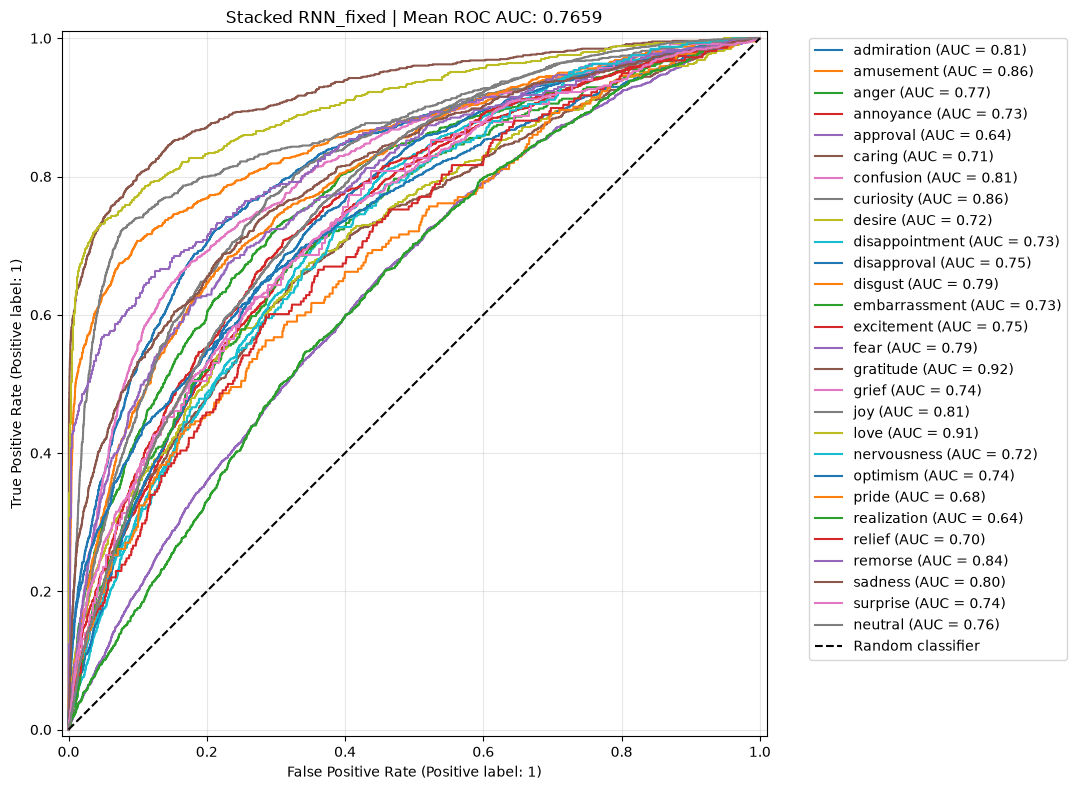

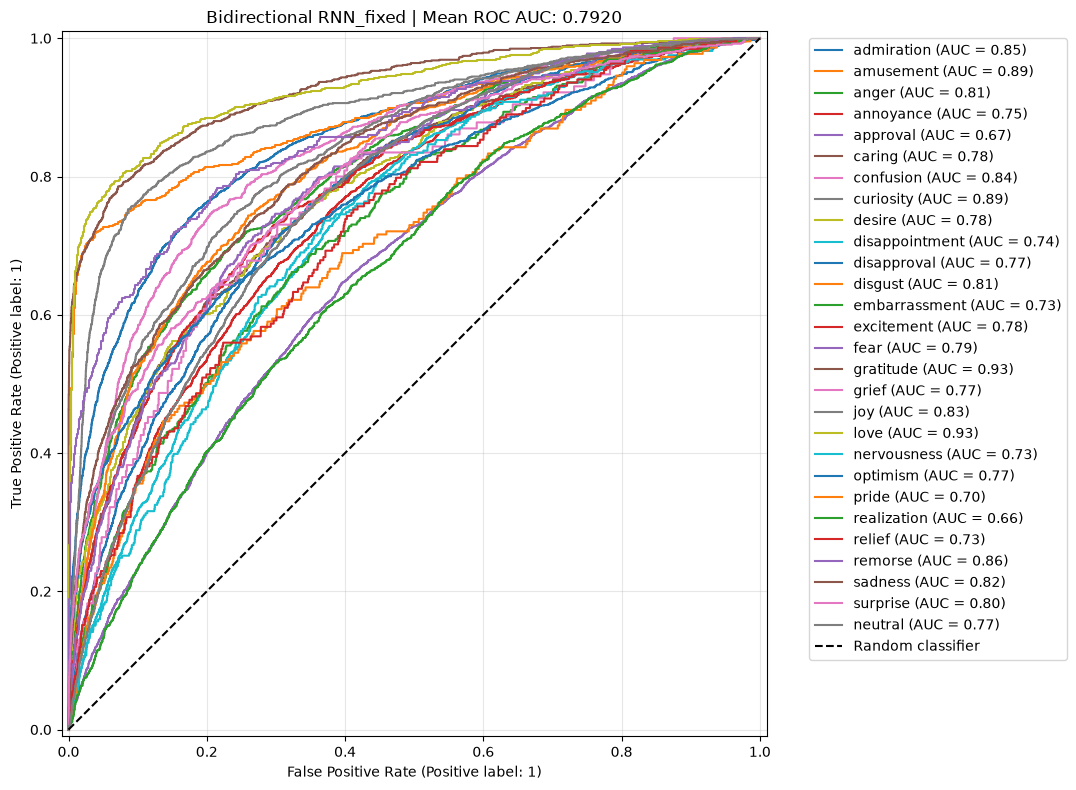

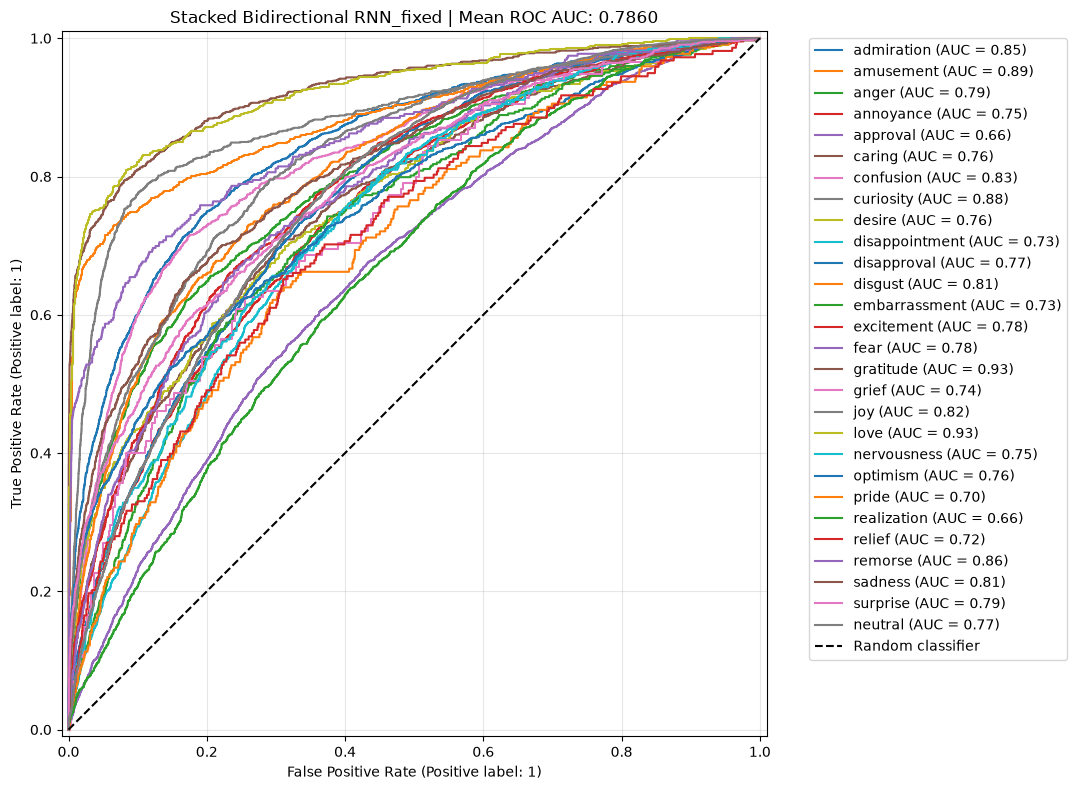

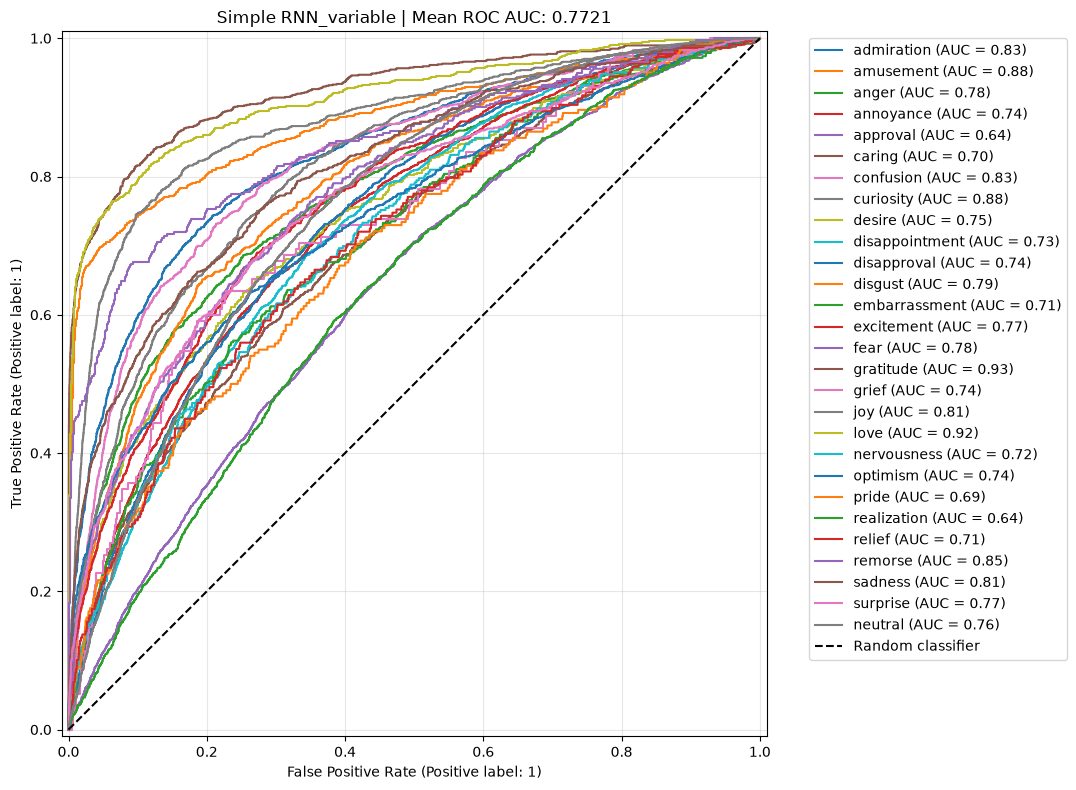

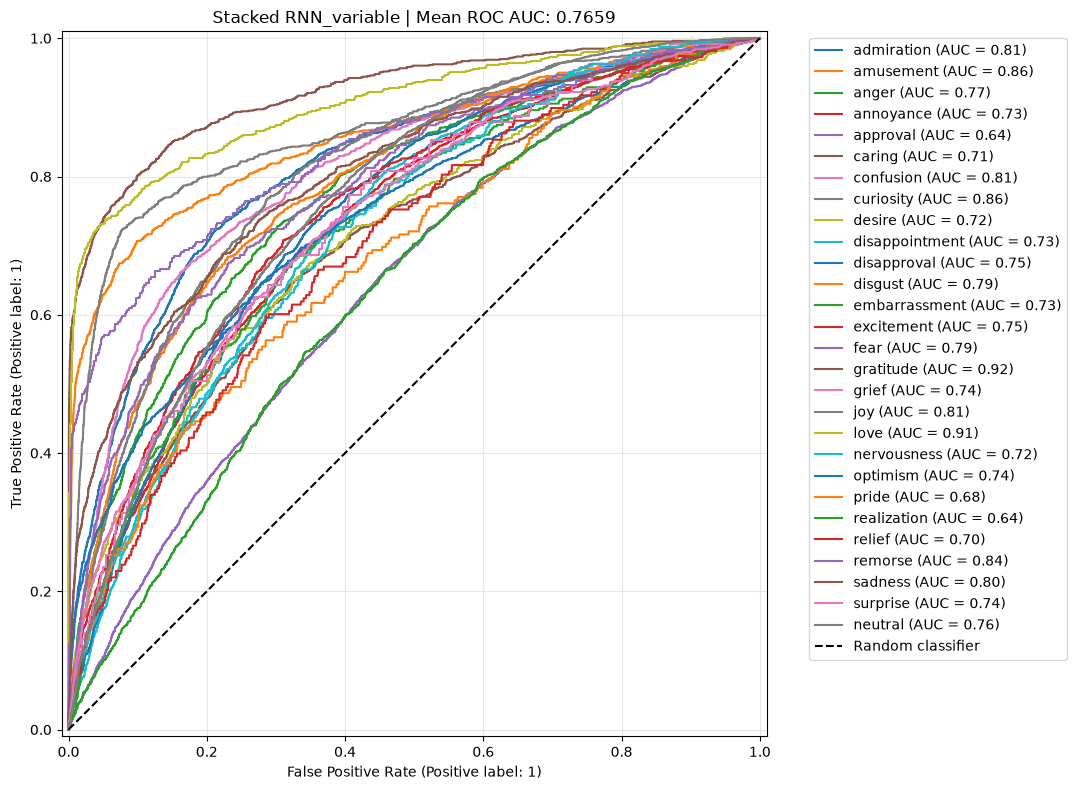

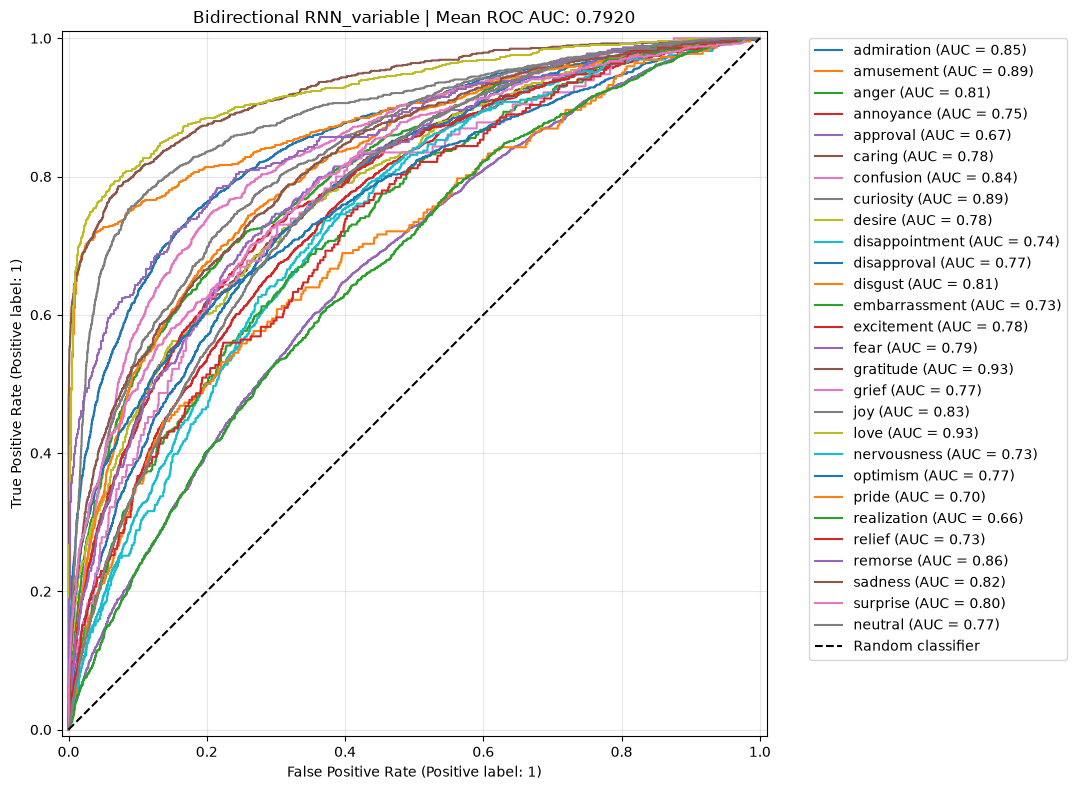

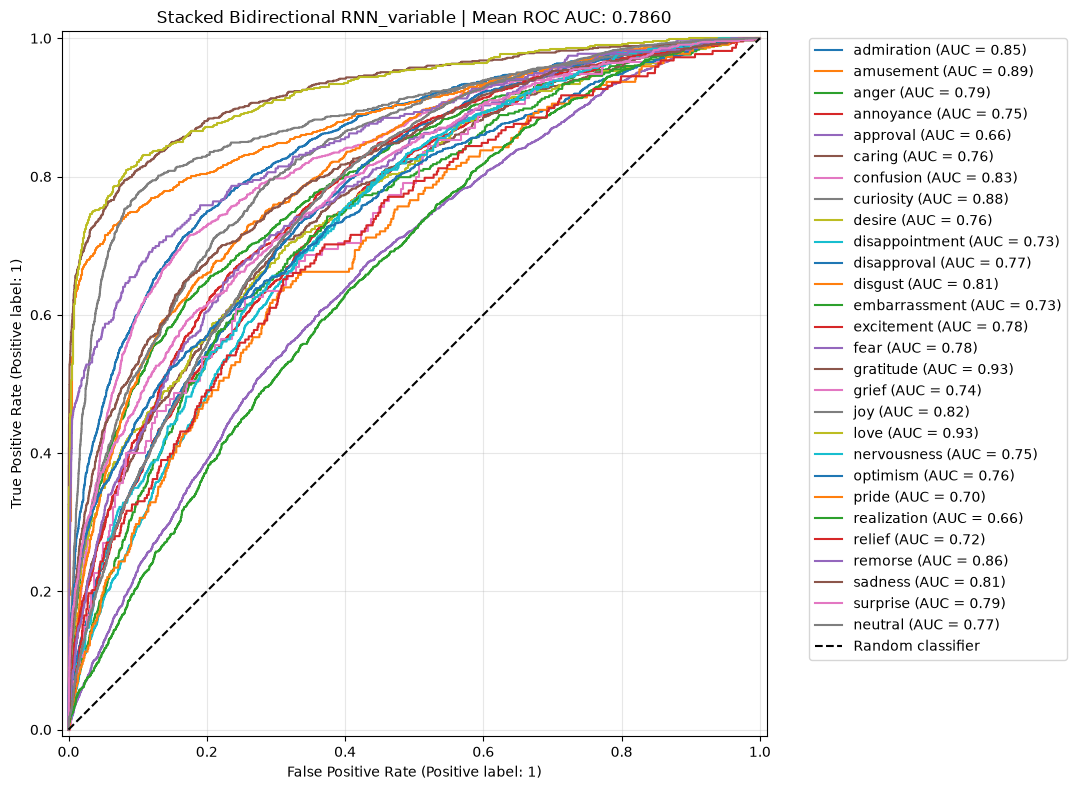

In [ ]:
for name, prediction in predictions.items():
    fig, ax = plt.subplots(figsize=(12, 8))

    mean_auc = plot_roc_curve(
        y_true=prediction["y_true"],
        y_prob=prediction["y_prob"],
        labels=emotions,
        ax=ax,
    )

    ax.set_title(f"{name} | Mean ROC AUC: {mean_auc:.4f}")

    plt.tight_layout()
    plt.show()

In [ ]:
results_df = (
    pd.DataFrame(test_results)
    .T
    .reset_index()
    .rename(columns={"index": "model"})
    .sort_values("auc", ascending=False)
)

results_df

,model,auc
2,Bidirectional RNN_fixed,0.791992
6,Bidirectional RNN_variable,0.791992
7,Stacked Bidirectional RNN_variable,0.785960
3,Stacked Bidirectional RNN_fixed,0.785960
4,Simple RNN_variable,0.772060
0,Simple RNN_fixed,0.772060
1,Stacked RNN_fixed,0.765906
5,Stacked RNN_variable,0.765906


Inspect the best model performance closer. Come up with some sentences (in English). Does the model output sensible results?

In [ ]:
@torch.no_grad()
def label_text(text: str, model, threshold: float = 0.5, max_length: int | None = None) -> list[str]:
    '''Computes the model output for `text` and outputs a list of emotions that have a probability of at least `threshold`

    Arguments:
        text: text to label
        model: model to use
        threshold: threshold to use
        max_length: max length for tokenization

    Return:
        List of predicted emotion labels'''

    model.eval()

    tokens = tokenizer.encode(
        text,
        truncation=True,
        max_length=max_length,
    )

    x = torch.tensor(
        [tokens],
        dtype=torch.long,
        device=DEVICE,
    )

    lengths = torch.tensor([len(tokens)])

    logits = model(x, lengths)
    probabilities = torch.sigmoid(logits).squeeze(0)

    predicted_labels = [
        emotions[i]
        for i, probability in enumerate(probabilities)
        if probability >= threshold
    ]

    return predicted_labels

In [ ]:
def plot_emotion_scores(text: str, model, max_length: int | None = None, ax: plt.Axes | None = None):
    '''Plots a bar plot of emotion probabilities for given `text` using `model`.

    Arguments:
        text: text to label
        model: model to use
        max_length: max length for tokenization
        ax: axes to plot on'''

    model.eval()

    tokens = tokenizer.encode(
        text,
        truncation=True,
        max_length=max_length,
    )

    x = torch.tensor(
        [tokens],
        dtype=torch.long,
        device=DEVICE,
    )

    lengths = torch.tensor([len(tokens)])

    logits = model(x, lengths)
    probabilities = torch.sigmoid(logits).squeeze(0).detach().cpu().numpy()

    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 8))

    indices = np.argsort(probabilities)

    ax.barh(
        np.array(emotions)[indices],
        probabilities[indices],
        edgecolor="black",
    )

    ax.set_title("Emotion distribution")
    ax.set_xlabel("Probability")
    ax.set_xlim(0, 1)
    ax.grid(axis="x", alpha=0.3)

    plt.tight_layout()
    return probabilities

For each of your texts get a list of emotion labels and plot emotion scores

In [ ]:
texts = [
    "I am so happy that everything worked out!",
    "I cannot believe you did this to me.",
    "Thank you so much for helping me.",
    "I am really worried about what happens next.",
    "That was absolutely hilarious!",
]

In [ ]:
best_model_name = results_df.iloc[0]["model"]
best_model = trained_models[best_model_name]

best_model_name

'Bidirectional RNN_fixed'


Text: I am so happy that everything worked out!
Predicted emotions: ['excitement', 'joy']


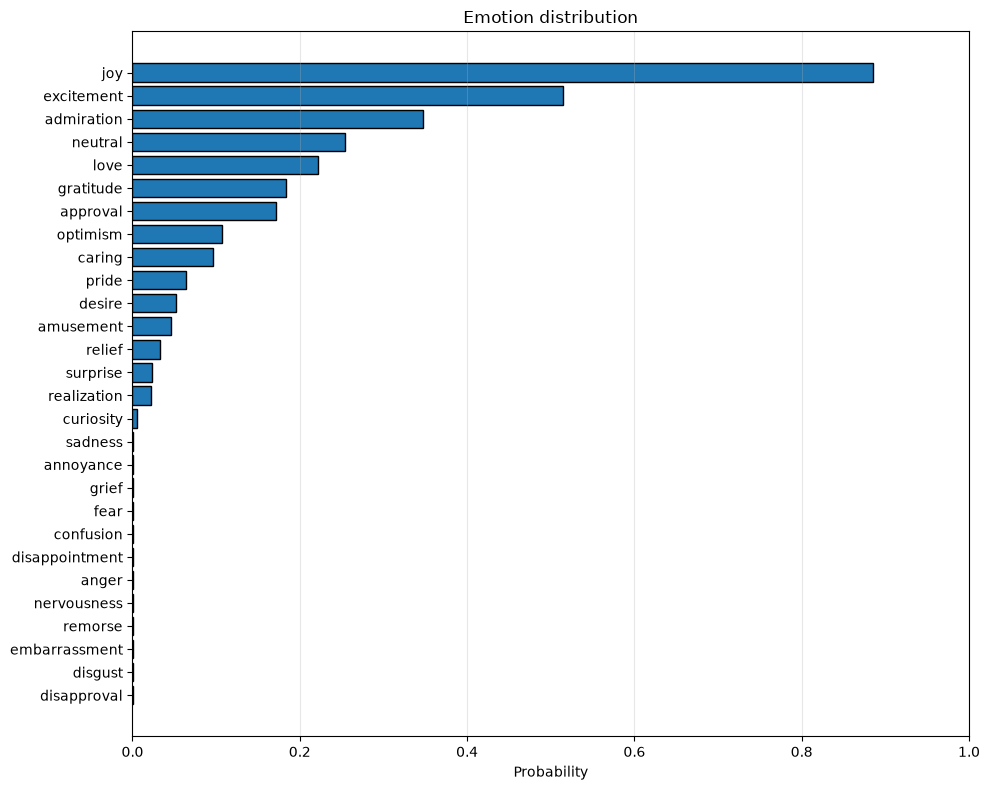


Text: I cannot believe you did this to me.
Predicted emotions: ['neutral']


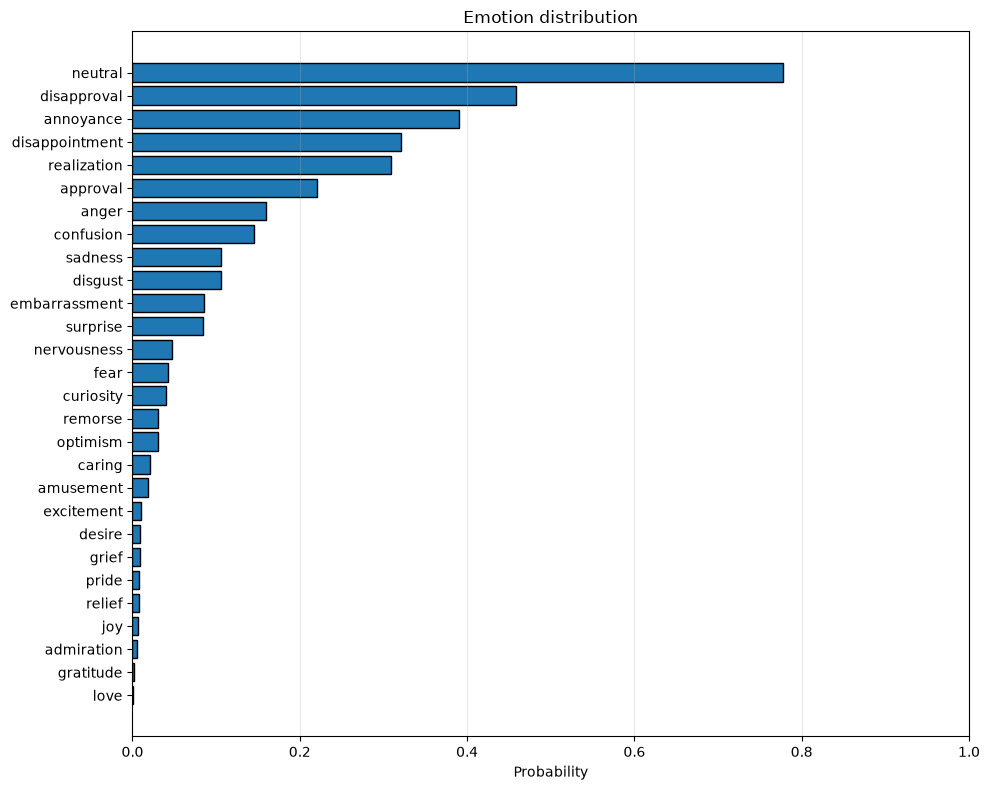


Text: Thank you so much for helping me.
Predicted emotions: ['gratitude']


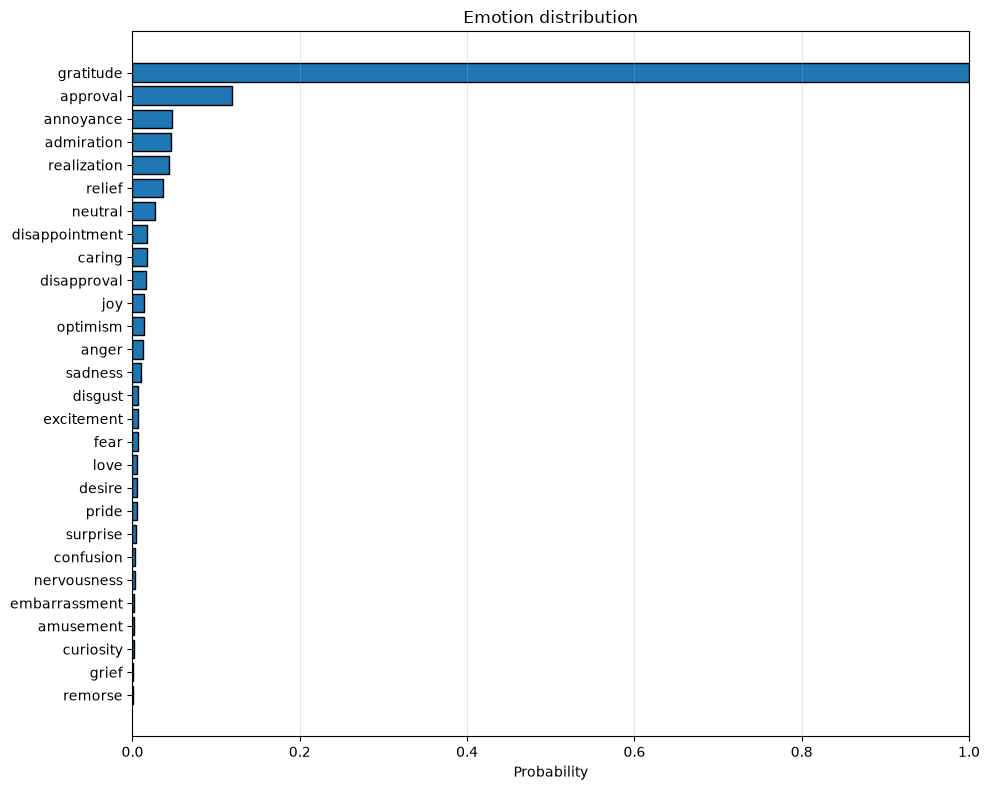


Text: I am really worried about what happens next.
Predicted emotions: []


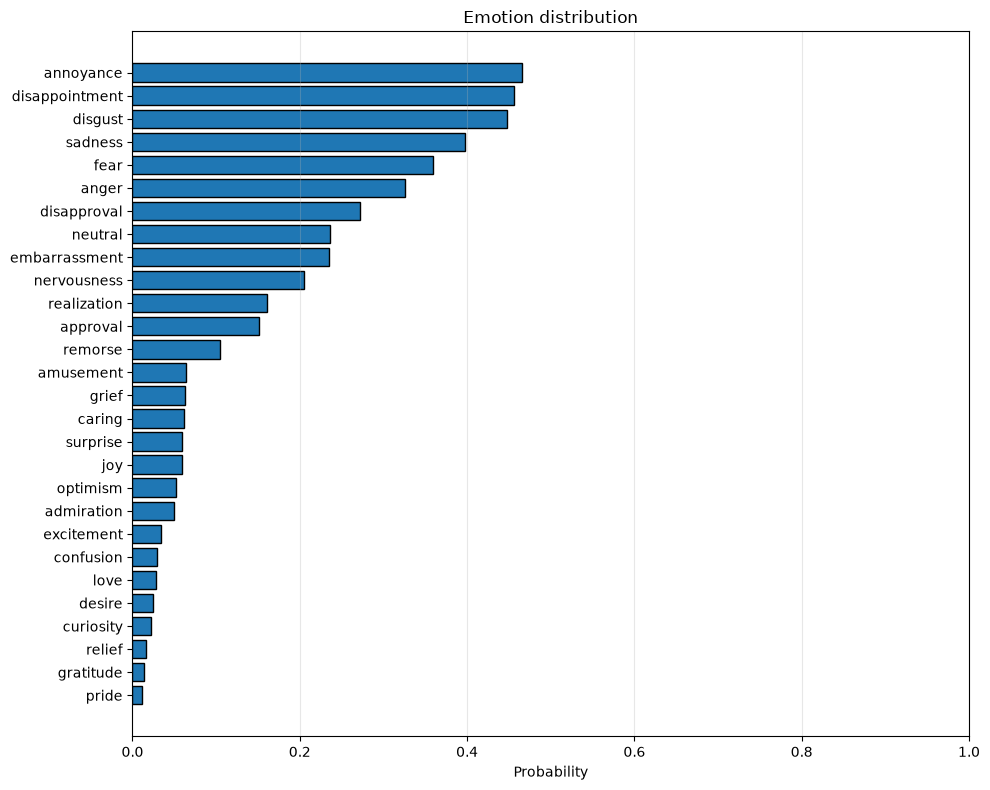


Text: That was absolutely hilarious!
Predicted emotions: ['admiration', 'amusement', 'joy']


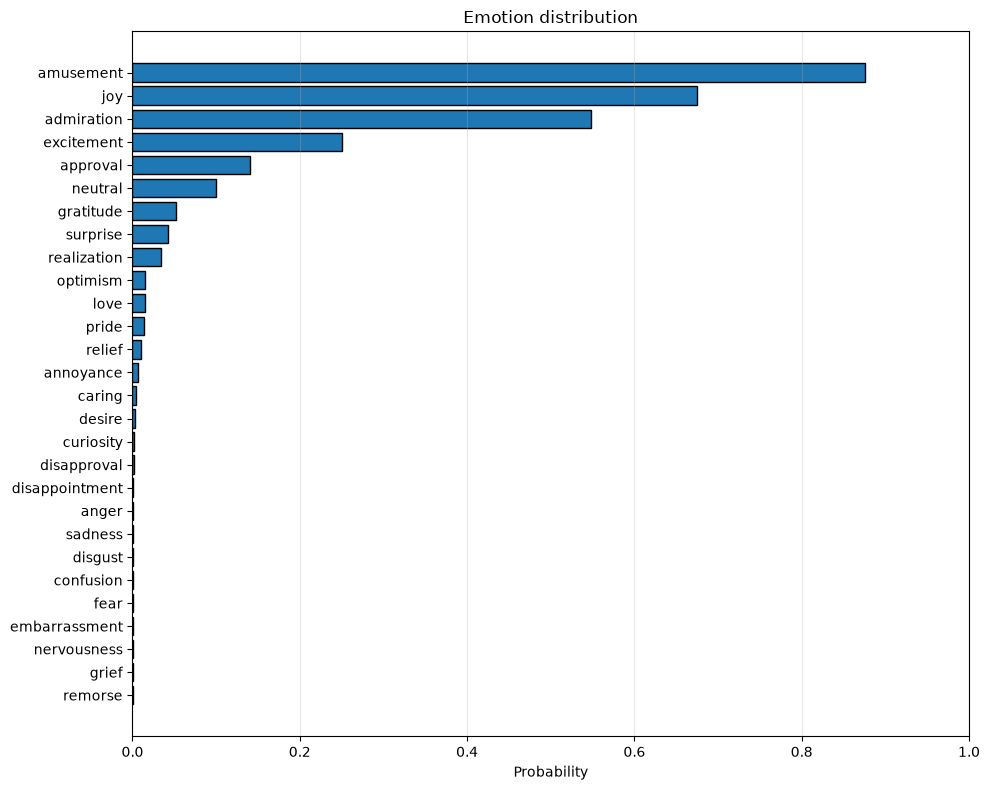

In [ ]:
for text in texts:
    predicted = label_text(
        text=text,
        model=best_model,
        threshold=0.5,
        max_length=44,
    )

    print(f"\nText: {text}")
    print(f"Predicted emotions: {predicted}")

    plot_emotion_scores(
        text=text,
        model=best_model,
        max_length=44,
    )

    plt.show()


# Bonus

Train and evaluate the same model as your best one, but use a different cell type

In [ ]:
gru_model = get_model(
    units=64,
    n_tokens=len(tokenizer),
    n_labels=len(emotions),
    pad_token_id=tokenizer.pad_token_id,
    n_stacks=1,
    bidirectional=True,
    name="Bidirectional GRU",
    cell_type=nn.GRU,
).to(DEVICE)

In [ ]:
criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.AdamW(
    gru_model.parameters(),
    lr=1e-3
)

callbacks = get_callbacks(
    model_name="Bidirectional GRU_fixed",
    optimizer=optimizer
)

In [ ]:
gru_model, gru_history = fit(
    model=gru_model,
    train_loader=loader["fixed"]["train_loader"],
    valid_loader=loader["fixed"]["test_loader"],
    criterion=criterion,
    optimizer=optimizer,
    callbacks=callbacks,
    device=DEVICE,
    calculate_metrics=calculate_metrics,
    epochs=30
)

Epoch [1/30] Train Loss: 0.3097 | Valid Loss: 0.2758 | AUC: 0.6316 | F1 Macro: 0.0559 | F1 Micro: 0.2533
Epoch [2/30] Train Loss: 0.2743 | Valid Loss: 0.2608 | AUC: 0.6900 | F1 Macro: 0.1031 | F1 Micro: 0.3138
Epoch [3/30] Train Loss: 0.2615 | Valid Loss: 0.2521 | AUC: 0.7209 | F1 Macro: 0.1369 | F1 Micro: 0.3594
Epoch [4/30] Train Loss: 0.2513 | Valid Loss: 0.2439 | AUC: 0.7438 | F1 Macro: 0.1621 | F1 Micro: 0.3827
Epoch [5/30] Train Loss: 0.2430 | Valid Loss: 0.2379 | AUC: 0.7621 | F1 Macro: 0.1882 | F1 Micro: 0.3981
Epoch [6/30] Train Loss: 0.2360 | Valid Loss: 0.2344 | AUC: 0.7727 | F1 Macro: 0.2084 | F1 Micro: 0.4096
Epoch [7/30] Train Loss: 0.2303 | Valid Loss: 0.2317 | AUC: 0.7798 | F1 Macro: 0.2253 | F1 Micro: 0.4228
Epoch [8/30] Train Loss: 0.2255 | Valid Loss: 0.2304 | AUC: 0.7859 | F1 Macro: 0.2367 | F1 Micro: 0.4279
Epoch [9/30] Train Loss: 0.2210 | Valid Loss: 0.2296 | AUC: 0.7892 | F1 Macro: 0.2469 | F1 Micro: 0.4373
Epoch [10/30] Train Loss: 0.2173 | Valid Loss: 0.2295 |

In [ ]:
y_true, y_prob = predict_dataset(
    model=gru_model,
    data_loader=loader["fixed"]["test_loader"],
    device=DEVICE
)

gru_metrics = calculate_metrics(y_true, y_prob)

gru_metrics

{'auc': 0.7957590401554103,
 'f1_macro': 0.29620347093766686,
 'f1_micro': 0.4617672474427765}

In [ ]:
test_results[name] = calculate_metrics(y_true, y_prob)
lstm_metrics = calculate_metrics(
    predictions["Bidirectional RNN_fixed"]["y_true"],
    predictions["Bidirectional RNN_fixed"]["y_prob"]
)
comparison = pd.DataFrame([
    {
        "model": "Bidirectional LSTM",
        **lstm_metrics
    },
    {
        "model": "Bidirectional GRU",
        **gru_metrics
    }
])

comparison

,model,auc,f1_macro,f1_micro
0,Bidirectional LSTM,0.791992,0.293410,0.456737
1,Bidirectional GRU,0.795759,0.296203,0.461767


In [ ]:
lstm_model = trained_models["Bidirectional RNN_fixed"]

comparison["parameters"] = [
    sum(p.numel() for p in lstm_model.parameters()),
    sum(p.numel() for p in gru_model.parameters())
]

comparison

,model,auc,f1_macro,f1_micro,parameters
0,Bidirectional LSTM,0.791992,0.293410,0.456737,3303132
1,Bidirectional GRU,0.795759,0.296203,0.461767,3286492
